<a href="https://colab.research.google.com/github/harshjxdaun/Placement-Predictor/blob/main/PlacementPredictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd

## importing the dataset

In [8]:
df = pd.read_csv('/content/sample_data/placement.csv')

In [34]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


## Preprocessing (EDA + feature selection)

In [10]:
df = df.iloc[:,1:]

In [11]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [12]:
import matplotlib.pyplot as plt

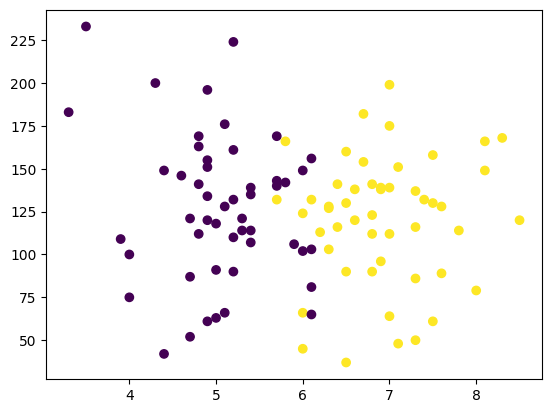

In [13]:
plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

In [14]:
X = df.iloc[:,0:2]
y= df.iloc[:,-1]

In [15]:
X.head()

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [16]:
y.head()

,placement
0,1
1,0
2,0
3,1
4,0


## Split the dataset

In [17]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1)

In [18]:
X_train

,cgpa,iq
40,4.9,134.0
31,3.9,109.0
55,7.8,114.0
37,8.1,149.0
30,7.6,128.0
...,...,...
22,4.9,120.0
49,5.4,135.0
47,5.2,161.0
18,4.0,100.0


In [19]:
X_test

,cgpa,iq
68,4.0,75.0
9,5.1,66.0
3,7.4,132.0
94,4.7,52.0
23,4.7,87.0
61,7.3,137.0
62,6.0,102.0
46,5.3,114.0
93,6.8,112.0
76,4.9,155.0


In [20]:
y_train

,placement
40,0
31,0
55,1
37,1
30,1
...,...
22,0
49,0
47,0
18,0


In [21]:
y_test

,placement
68,0
9,0
3,1
94,0
23,0
61,1
62,0
46,0
93,1
76,0


## Scale the Values

In [22]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()

In [23]:
X_train = scalar.fit_transform(X_train)

In [24]:
X_train

array([[-1.00068061,  0.20429375],
       [-1.88450058, -0.4219473 ],
       [ 1.5623973 , -0.29669909],
       [ 1.8275433 ,  0.58003838],
       [ 1.38563331,  0.0539959 ],
       [-1.08906261,  1.08103122],
       [ 0.94372332, -1.94997547],
       [ 0.85534133, -0.34679838],
       [-1.4425906 , -2.10027332],
       [ 1.29725131,  0.10409518],
       [ 0.41343134,  0.85558444],
       [-0.29362463,  0.3545916 ],
       [-1.08906261,  0.37964124],
       [ 1.7391613 , -1.17343657],
       [-1.17744461, -0.1213516 ],
       [-0.82391662,  1.25637871],
       [-0.02847864, -0.04620267],
       [ 2.00430729,  1.05598158],
       [ 0.05990335, -1.52413156],
       [ 0.76695933, -0.74759265],
       [-0.55877063, -0.47204659],
       [-0.29362463,  0.42974053],
       [-0.29362463,  0.15419446],
       [-0.55877063, -0.29669909],
       [ 0.23666735,  0.0539959 ],
       [-0.91229861, -0.19650053],
       [ 0.94372332,  0.63013766],
       [ 0.59019534,  1.40667657],
       [ 0.05990335,

In [25]:
X_test = scalar.transform(X_test)

In [26]:
X_test

array([[-1.79611859, -1.27363513],
       [-0.82391662, -1.49908191],
       [ 1.20886932,  0.15419446],
       [-1.17744461, -1.8497769 ],
       [-1.17744461, -0.97303943],
       [ 1.12048732,  0.27944267],
       [-0.02847864, -0.5972948 ],
       [-0.64715262, -0.29669909],
       [ 0.67857733, -0.34679838],
       [-1.00068061,  0.73033623]])

## Train the Model

In [27]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

In [28]:
clf.fit(X_train,y_train)

LogisticRegression()

## Test the Model

In [29]:
y_pred = clf.predict(X_test)

In [30]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9

## Visualize the Prediction

In [31]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

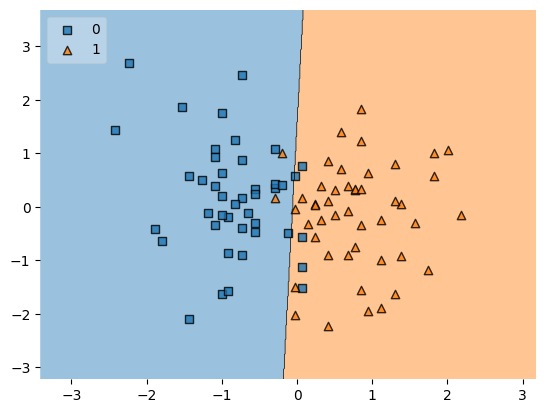

In [32]:
plot_decision_regions(X_train,y_train.values, clf=clf, legend=2)

## Make it deployable

In [35]:
import pickle

In [37]:
pickle.dump(clf,open('PlacePredModel.pkl','wb'))